
# Titanic: ¿qué factores se asociaron con sobrevivir?

Análisis exploratorio con pandas, matplotlib y seaborn sobre 891 pasajeros del Titanic.

**Pregunta:** ¿qué factores (sexo, clase, edad, compañía de viaje y tarifa) se asociaron más con sobrevivir?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
df.info()
print()
print("Valores vacios por columna:")
print(df.isnull().sum())
print()
print("Filas y columnas:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB

Valores vacios por columna:
survived         0
pclass           0
sex              0
age     

In [3]:
df_limpio = df.copy()
df_limpio = df_limpio.drop(columns=["deck"])
puerto = df_limpio["embarked"].mode()[0]
df_limpio["embarked"] = df_limpio["embarked"].fillna(puerto)
df_limpio["embark_town"] = df_limpio["embark_town"].fillna(
    df_limpio["embark_town"].mode()[0]
)
df_limpio["age"] = df_limpio["age"].fillna(
    df_limpio.groupby(["pclass", "sex",])["age"].transform("median")
)
print("Vacios despues de limpiar:")
print(df_limpio.isnull().sum().sum())
print("Filas y columnas:", df_limpio.shape)

Vacios despues de limpiar:
0
Filas y columnas: (891, 14)


In [4]:
print("Tasa de supervivencias global (%):", round(df_limpio["survived"].mean() * 100,1))
print()
print("Por sexo (%):")
print(df_limpio.groupby("sex")["survived"].mean().mul(100).round(1))
print()
print("por clase (%):")
print(df_limpio.groupby("pclass")["survived"].mean().mul(100).round(1))
print()
print("Por sexo y clase (%):")
print(df_limpio.groupby(["pclass", "sex"])["survived"].mean().mul(100).round(1))


Tasa de supervivencias global (%): 38.4

Por sexo (%):
sex
female    74.2
male      18.9
Name: survived, dtype: float64

por clase (%):
pclass
1    63.0
2    47.3
3    24.2
Name: survived, dtype: float64

Por sexo y clase (%):
pclass  sex   
1       female    96.8
        male      36.9
2       female    92.1
        male      15.7
3       female    50.0
        male      13.5
Name: survived, dtype: float64


## Limpieza de datos
- Se elimina `deck`: el 77,2 % de sus valores está vacío.
- Los 2 vacíos de `embarked` y `embark_town` se rellenan con el valor más frecuente.
- Las 177 edades vacías (19,9 %) se rellenan con la mediana por clase y sexo. El análisis por edad usa solo las edades reales.

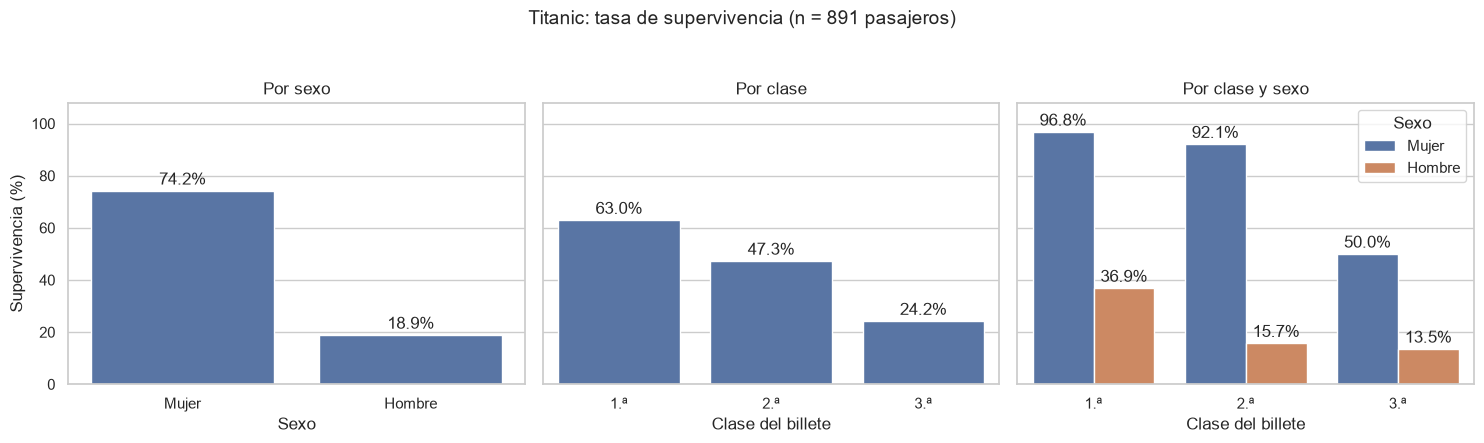

In [5]:
d = df_limpio.copy()
d["sexo"] = d["sex"].map({"female": "Mujer", "male": "Hombre"})
d["clase"] = d["pclass"].map({1: "1.ª", 2: "2.ª", 3: "3.ª"})
d["supervivencia"] = d["survived"] * 100

orden_sexo = ["Mujer", "Hombre"]
orden_clase = ["1.ª", "2.ª", "3.ª"]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

sns.barplot(data=d, x="sexo", y="supervivencia", order=orden_sexo,
            ax=axes[0], errorbar=None)
axes[0].set_title("Por sexo")
axes[0].set_xlabel("Sexo")

sns.barplot(data=d, x="clase", y="supervivencia", order=orden_clase,
            ax=axes[1], errorbar=None)
axes[1].set_title("Por clase")
axes[1].set_xlabel("Clase del billete")

sns.barplot(data=d, x="clase", y="supervivencia", hue="sexo",
            order=orden_clase, hue_order=orden_sexo, ax=axes[2], errorbar=None)
axes[2].set_title("Por clase y sexo")
axes[2].set_xlabel("Clase del billete")
axes[2].legend(title="Sexo")

for ax in axes:
    ax.set_ylim(0, 108)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=2)
axes[0].set_ylabel("Supervivencia (%)")
axes[1].set_ylabel("")
axes[2].set_ylabel("")

fig.suptitle("Titanic: tasa de supervivencia (n = 891 pasajeros)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig("supervivencia_sexo_clase.png", dpi=150, bbox_inches="tight")
plt.show()

Por grupo de edad (solo edades reales):
            supervivencia_%  pasajeros
grupo_edad                            
0-12                   58.0         69
13-18                  42.9         70
19-35                  38.3        358
36-60                  40.0        195
61+                    22.7         22

Viaja solo (True) o acompañado (False):
       supervivencia_%  pasajeros
alone                            
False             50.6        354
True              30.4        537

Tarifa mediana según supervivencia (0 = no, 1 = sí):
survived
0    10.5
1    26.0
Name: fare, dtype: float64

Tarifa mediana por clase:
pclass
1    60.29
2    14.25
3     8.05
Name: fare, dtype: float64


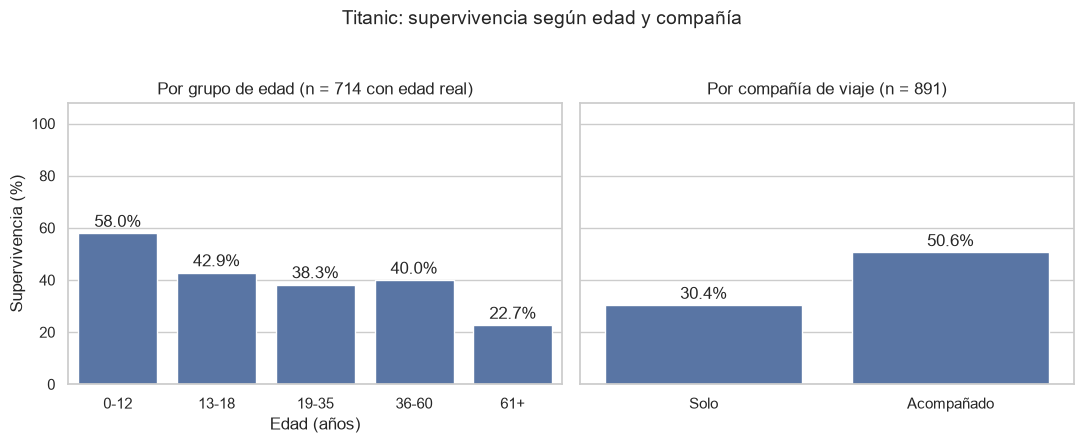

In [6]:
# Edad: solo con edades reales (sin rellenar), 714 de 891 pasajeros
df_edad = df.dropna(subset=["age"]).copy()
df_edad["grupo_edad"] = pd.cut(
    df_edad["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["0-12", "13-18", "19-35", "36-60", "61+"]
)

res_edad = df_edad.groupby("grupo_edad", observed=True)["survived"].agg(["mean", "count"])
res_edad["mean"] = (res_edad["mean"] * 100).round(1)
res_edad.columns = ["supervivencia_%", "pasajeros"]
print("Por grupo de edad (solo edades reales):")
print(res_edad)
print()

res_solo = df_limpio.groupby("alone")["survived"].agg(["mean", "count"])
res_solo["mean"] = (res_solo["mean"] * 100).round(1)
res_solo.columns = ["supervivencia_%", "pasajeros"]
print("Viaja solo (True) o acompañado (False):")
print(res_solo)
print()

print("Tarifa mediana según supervivencia (0 = no, 1 = sí):")
print(df_limpio.groupby("survived")["fare"].median().round(2))
print()
print("Tarifa mediana por clase:")
print(df_limpio.groupby("pclass")["fare"].median().round(2))

# Gráfico
d2 = df_limpio.copy()
d2["viaje"] = d2["alone"].map({True: "Solo", False: "Acompañado"})
d2["supervivencia"] = d2["survived"] * 100
df_edad["supervivencia"] = df_edad["survived"] * 100

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

sns.barplot(data=df_edad, x="grupo_edad", y="supervivencia", ax=axes[0], errorbar=None)
axes[0].set_title("Por grupo de edad (n = 714 con edad real)")
axes[0].set_xlabel("Edad (años)")

sns.barplot(data=d2, x="viaje", y="supervivencia", order=["Solo", "Acompañado"],
            ax=axes[1], errorbar=None)
axes[1].set_title("Por compañía de viaje (n = 891)")
axes[1].set_xlabel("")

for ax in axes:
    ax.set_ylim(0, 108)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=2)
axes[0].set_ylabel("Supervivencia (%)")
axes[1].set_ylabel("")

fig.suptitle("Titanic: supervivencia según edad y compañía", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig("supervivencia_edad_compania.png", dpi=150, bbox_inches="tight")
plt.show()


## Conclusiones

**Pregunta:** ¿qué factores se asociaron más con sobrevivir al hundimiento del Titanic?

Sobrevivió el 38,4 % de los 891 pasajeros analizados.

1. **Sexo (el factor más fuerte).** Sobrevivió el 74,2 % de las mujeres frente al 18,9 % de los hombres.
2. **Clase del billete.** La supervivencia bajó al empeorar la clase: 63,0 % en 1.ª, 47,3 % en 2.ª y 24,2 % en 3.ª.
3. **Sexo y clase juntos.** Más del 90 % de las mujeres de 1.ª y 2.ª clase sobrevivió (96,8 % y 92,1 %), frente al 50,0 % de las de 3.ª. Entre los hombres, solo los de 1.ª clase superaron el 20 % (36,9 %); en 2.ª y 3.ª fue del 15,7 % y el 13,5 %.
4. **Edad.** Los niños de hasta 12 años sobrevivieron más (58,0 %); entre los 13 y los 60 años los valores fueron parecidos (38,3 % a 42,9 %). Los mayores de 60 años bajan a 22,7 %, pero son solo 22 personas.
5. **Viajar solo.** Los que viajaban solos sobrevivieron menos (30,4 % frente a 50,6 %), pero en buena parte porque el 76,5 % de ellos eran hombres (entre los acompañados, el 46,9 %). Dentro de cada sexo el patrón no es uniforme: las mujeres solas sobrevivieron algo más que las acompañadas (78,6 % frente a 71,3 %) y los hombres solos, menos (15,6 % frente a 27,1 %).
6. **Tarifa.** Los supervivientes pagaron una tarifa mediana de 26,0 £ frente a 10,5 £ (libras de 1912; el dataset no documenta la moneda). La tarifa está muy ligada a la clase (mediana de 60,29 £ en 1.ª, 14,25 £ en 2.ª y 8,05 £ en 3.ª) y aporta poco por sí sola: dentro de cada clase la diferencia se mantiene en 1.ª y 2.ª y casi desaparece en 3.ª.

### Límites del análisis
- Son **asociaciones, no causas**. Influyeron factores que no se miden aquí, como la ubicación del camarote y las órdenes de evacuación ("mujeres y niños primero").
- Faltaba el 19,9 % de las edades (177 de 891). Se rellenaron con la mediana por clase y sexo para el análisis general, pero el análisis por edad usa solo las edades reales (714).
- Se eliminó la columna `deck` por tener el 77,2 % de valores vacíos, y se rellenaron con el valor más frecuente las 2 filas sin puerto de embarque.
- Algunos grupos son pequeños (por ejemplo, 22 personas de más de 60 años o 94 mujeres de 1.ª clase), así que sus porcentajes son menos fiables.
- Los datos son una muestra de 891 pasajeros, no todas las personas que iban a bordo.